In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print(df.shape)
df.info()
print(df["Churn"].value_counts())

(7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null

In [2]:
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.drop(columns=["customerID"], inplace=True)


In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df["TotalCharges"].isna().sum())

11


In [5]:
df = df.dropna()

In [6]:
df.head(5)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
df["Churn"] = (df["Churn"] == "Yes").astype(int)

In [8]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

In [9]:
X = pd.get_dummies(X, drop_first=True)

In [10]:
X

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,False,True,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,True,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,True,False,False,True,False,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,True,False,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,False,False,False,True,False,False,...,False,False,False,False,False,False,True,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,0,24,84.80,1990.50,True,True,True,True,False,True,...,False,True,False,True,True,False,True,False,False,True
7039,0,72,103.20,7362.90,False,True,True,True,False,True,...,False,True,False,True,True,False,True,True,False,False
7040,0,11,29.60,346.45,False,True,True,False,True,False,...,False,False,False,False,False,False,True,False,True,False
7041,1,4,74.40,306.60,True,True,False,True,False,True,...,False,False,False,False,False,False,True,False,False,True


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

In [12]:

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [13]:
import numpy as np
from sklearn.linear_model import LogisticRegressionCV

clf = LogisticRegressionCV(Cs=np.logspace(-3, 2, 20), cv=5, penalty="l2",
                           solver="saga", scoring="roc_auc", max_iter=5000)
clf.fit(X_train_s, y_train)

/opt/anaconda3/envs/Machinelearning/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2092: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/opt/anaconda3/envs/Machinelearning/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2123: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
/opt/anaconda3/envs/Machinelearning/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:21

,"Cs Cs: int or list of floats, default=10Each of the values in Cs describes the inverse of regularizationstrength. If Cs is as an int, then a grid of Cs values are chosenin a logarithmic scale between 1e-4 and 1e4.Like in support vector machines, smaller values specify strongerregularization.",array([1.0000...00000000e+02])
,"cv cv: int or cross-validation generator, default=NoneThe default cross-validation generator used is Stratified K-Folds.If an integer is provided, it specifies the number of folds, `n_folds`, used.See the module :mod:`sklearn.model_selection` module for thelist of possible cross-validation objects... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"penalty penalty: {'l1', 'l2', 'elasticnet'}, default='l2'Specify the norm of the penalty:- `'l2'`: add an L2 penalty term (used by default);- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l2'
,"scoring scoring: str or callable, default=NoneThe scoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: :ref:`accuracy <accuracy_score>` is used... versionchanged:: 1.11 The default will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11.",'roc_auc'
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' might be slower in :class:`LogisticRegressionCV` because it does not handle warm-starting.- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) chosen and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0

In [14]:
coefs = pd.Series(clf.coef_[0], index=X.columns).sort_values()

In [15]:
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, roc_auc_score)

In [16]:
proba = clf.predict_proba(X_test_s)[:, 1]
pred = (proba >= 0.5).astype(int)

In [17]:
print("baseline accuracy:", 1 - y_test.mean())


baseline accuracy: 0.7341862117981521


In [18]:
print("accuracy:", accuracy_score(y_test, pred))
print("AUC:", roc_auc_score(y_test, proba))

accuracy: 0.7981520966595593
AUC: 0.834981700151679


In [19]:
print(confusion_matrix(y_test, pred))

[[910 123]
 [161 213]]


In [20]:
compare = pd.DataFrame({
    "actual": y_test.values,
    "predicted": pred,
    "prob_churn": proba.round(2),
})
compare["match"] = compare["actual"] == compare["predicted"]
print(compare.head(10))
print("matched:", compare["match"].sum(), "of", len(compare))

   actual  predicted  prob_churn  match
0       0          0        0.02   True
1       0          1        0.61  False
2       0          0        0.00   True
3       1          0        0.20  False
4       0          0        0.10   True
5       1          0        0.46  False
6       0          0        0.03   True
7       0          0        0.16   True
8       1          1        0.71   True
9       0          0        0.01   True
matched: 1123 of 1407


In [22]:
for d in [1, 2, 3, 5, 8,10, 12, 20, None]:
    t = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    tr = roc_auc_score(y_train, t.predict_proba(X_train)[:, 1])
    te = roc_auc_score(y_test, t.predict_proba(X_test)[:, 1])
    print(f"depth={str(d):<5} train AUC={tr:.3f}  test AUC={te:.3f}")

NameError: name 'DecisionTreeClassifier' is not defined

In [23]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=300, max_depth=8, min_samples_leaf=10,
    random_state=42, n_jobs=-1
)
rf.fit(X_train, y_train)

print("train AUC:", roc_auc_score(y_train, rf.predict_proba(X_train)[:, 1]))
print("test AUC: ", roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1]))

train AUC: 0.8827604525172691
test AUC:  0.8390635757955387


In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier

gb = HistGradientBoostingClassifier(
    learning_rate=0.05, max_depth=3, max_iter=300,
    l2_regularization=1.0, early_stopping=True, random_state=42
)
gb.fit(X_train, y_train)

print("train AUC:", roc_auc_score(y_train, gb.predict_proba(X_train)[:, 1]))
print("test AUC: ", roc_auc_score(y_test, gb.predict_proba(X_test)[:, 1]))

train AUC: 0.8657843335735744
test AUC:  0.8414979474144669


In [ ]:
from sklearn.inspection import permutation_importance

r = permutation_importance(
    gb, X_test, y_test, scoring="roc_auc",
    n_repeats=10, random_state=42, n_jobs=-1
)
imp = pd.Series(r.importances_mean, index=X.columns).sort_values(ascending=False)
print(imp.head(10))

tenure                            0.056039
Contract_Two year                 0.045980
InternetService_Fiber optic       0.025809
InternetService_No                0.018816
Contract_One year                 0.015768
TotalCharges                      0.005581
MonthlyCharges                    0.004751
PaperlessBilling_Yes              0.003765
PaymentMethod_Electronic check    0.003401
TechSupport_Yes                   0.002806
dtype: float64


In [ ]:
lr_top = coefs.abs().sort_values(ascending=False).head(10)
print(lr_top)

MonthlyCharges                    2.113552
tenure                            1.407669
InternetService_Fiber optic       1.242491
TotalCharges                      0.701346
Contract_Two year                 0.605315
StreamingTV_Yes                   0.451010
StreamingMovies_Yes               0.438475
MultipleLines_Yes                 0.317056
Contract_One year                 0.310529
PaymentMethod_Electronic check    0.182457
dtype: float64


In [24]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

# Load + clean (no get_dummies, no scaling here)
df = pd.read_csv(url).drop(columns=["customerID"])
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.dropna()
y = (df["Churn"] == "Yes").astype(int)
X = df.drop(columns=["Churn"])

# Which columns are numbers, which are text
num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(exclude="number").columns

# Preprocessing: different treatment per column type
prep = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

# Preprocessing + model in one object
model = Pipeline([
    ("prep", prep),
    ("clf", LogisticRegressionCV(Cs=np.logspace(-3, 2, 20), cv=5,
                                 scoring="roc_auc", max_iter=5000)),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

model.fit(X_train, y_train)
print("test AUC:", roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]))

/opt/anaconda3/envs/Machinelearning/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2092: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/opt/anaconda3/envs/Machinelearning/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2150: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(


test AUC: 0.8354812575386573


### What each part does
num_cols / cat_cols: pandas sorts the columns by type automatically.


ColumnTransformer: says "scale these columns, one-hot encode those columns". It replaces the manual get_dummies and scaler steps.


handle_unknown="ignore": if the test set has a category the training set never saw, it encodes all zeros instead of crashing. That matters in real use.



Pipeline: chains prep then clf. model.fit(X_train, y_train) runs the preprocessing and the training. model.predict_proba(X_test) runs the same preprocessing on new data automatically.


### Why this is better
Leakage fixed properly. In your earlier flow, the scaler was fit on all training data before cross-validation, so each CV fold's scaler had seen its own validation rows. Inside a pipeline, the scaler is refit on each fold's training part only.
One object to ship. joblib.dump(model, "churn.pkl") saves everything. A FastAPI endpoint can load it and take raw customer data. No manual encoding step to forget. This is the ML engineer part.
Fewer lines, fewer bugs.

In [25]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV

prep_gb = ColumnTransformer([
    ("num", "passthrough", num_cols),          # trees don't need scaling
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

pipe = Pipeline([
    ("prep", prep_gb),
    ("clf", HistGradientBoostingClassifier(random_state=42)),
])

param_grid = {
    "clf__learning_rate": [0.03, 0.1,0.2],
    "clf__max_depth": [1, 2, 3],
    "clf__max_iter": [50, 100, 200],
    "clf__l2_regularization": [1.0, 5.0, 20.0],
}

grid = GridSearchCV(pipe, param_grid, cv=5, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)

print("best params:", grid.best_params_)
print("best CV AUC:", grid.best_score_)
print("test AUC:   ", roc_auc_score(y_test, grid.predict_proba(X_test)[:, 1]))

best params: {'clf__l2_regularization': 1.0, 'clf__learning_rate': 0.2, 'clf__max_depth': 1, 'clf__max_iter': 200}
best CV AUC: 0.8499659883226574
test AUC:    0.8411161613285639


In [ ]:
import joblib
joblib.dump(grid.best_estimator_, "churn_model.pkl")

['churn_model.pkl']

In [ ]:
loaded = joblib.load("churn_model.pkl")

# one raw customer, exactly as it would arrive (no encoding, no scaling)
sample = X_test.iloc[[0]]
print(sample.T)
print("churn probability:", loaded.predict_proba(sample)[0, 1])

                                      974
gender                             Female
SeniorCitizen                           0
Partner                               Yes
Dependents                            Yes
tenure                                 59
PhoneService                          Yes
MultipleLines                          No
InternetService                       DSL
OnlineSecurity                         No
OnlineBackup                          Yes
DeviceProtection                       No
TechSupport                           Yes
StreamingTV                           Yes
StreamingMovies                       Yes
Contract                         Two year
PaperlessBilling                      Yes
PaymentMethod     Credit card (automatic)
MonthlyCharges                      75.95
TotalCharges                      4542.35
churn probability: 0.027684869631712756


In [26]:
pip install shap

Note: you may need to restart the kernel to use updated packages.


/opt/anaconda3/envs/Machinelearning/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


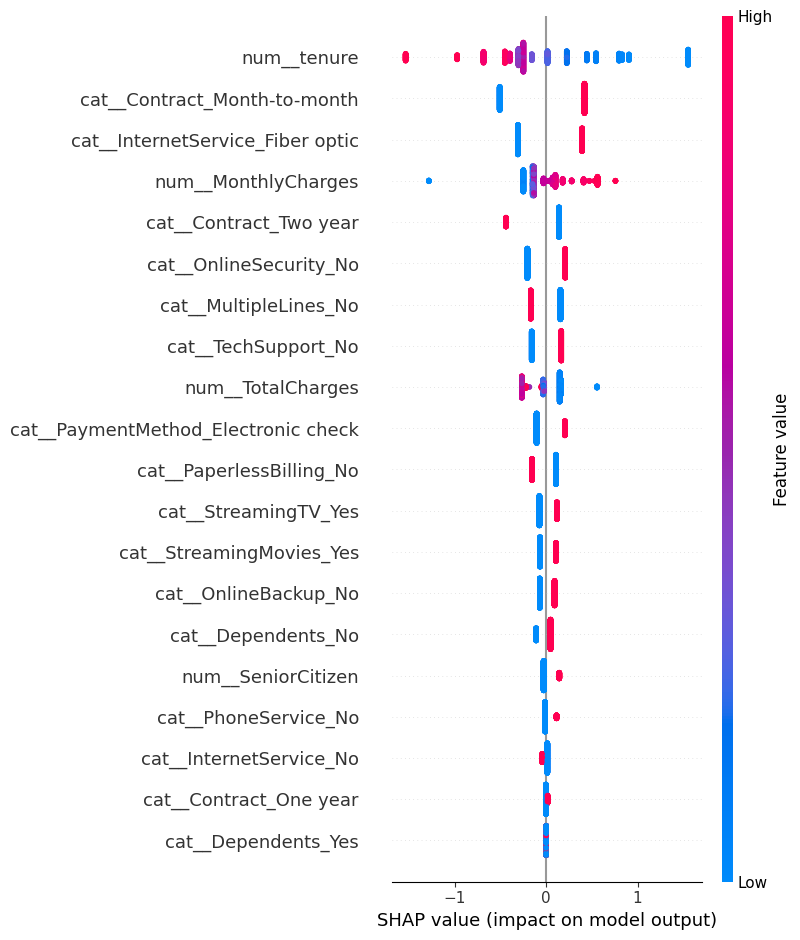

In [ ]:
import shap

best = grid.best_estimator_
prep_fit = best.named_steps["prep"]
gb_model = best.named_steps["clf"]

# Transform the data the way the pipeline does, and keep feature names
X_test_t = pd.DataFrame(
    prep_fit.transform(X_test),
    columns=prep_fit.get_feature_names_out()
)

explainer = shap.TreeExplainer(gb_model)
sv = explainer.shap_values(X_test_t)

# Global view: which features push predictions the most
shap.summary_plot(sv, X_test_t)

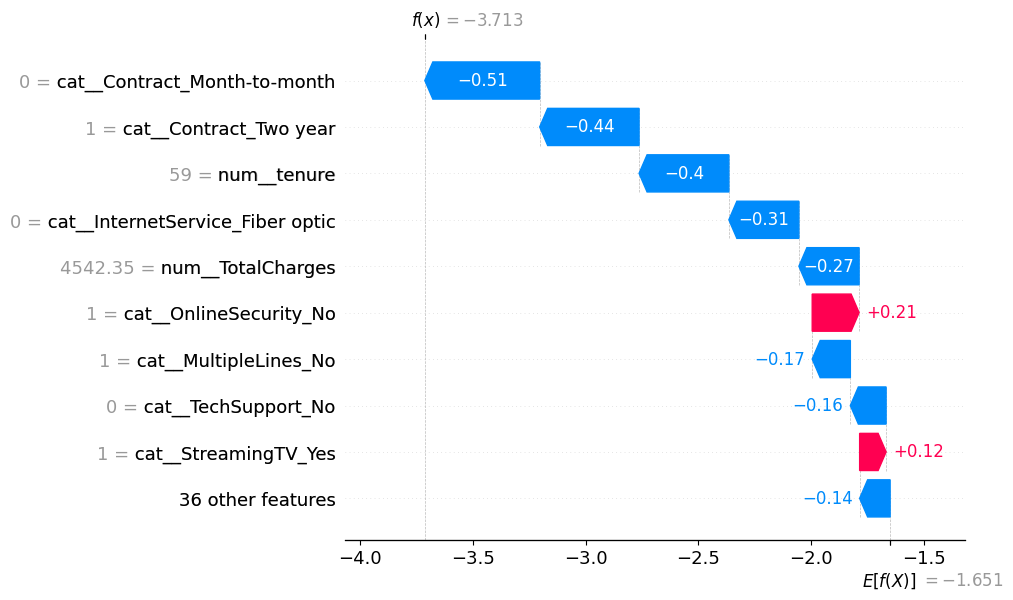

In [28]:
exp = explainer(X_test_t)
shap.plots.waterfall(exp[0])

In [29]:
import matplotlib.pyplot as plt

shap.summary_plot(sv, X_test_t, show=False)
plt.savefig("shap_summary.png", bbox_inches="tight", dpi=150)
plt.close()

shap.plots.waterfall(exp[0], show=False)
plt.savefig("shap_waterfall.png", bbox_inches="tight", dpi=150)
plt.close()